# 06 · Final Research — Validation, Diversity, and Ensemble Design

**Competition:** Kaggle Playground Series S6E9 — Predicting Electric Vehicle Purchases  
**Metric:** ROC-AUC  
**Final result:** **Private AUC 0.94544 · Rank 350 / 3576 · Top 9.8%**

This notebook is the project-level research report. Model training is separated into the canonical training notebooks:

- `01_logistic_baseline.ipynb`
- `02_lgb_exact.ipynb`
- `03_catboost.ipynb`
- `04_lgb_coarse.ipynb`
- `05_additive_xgb.ipynb`

The role of this notebook is different: it reconstructs the model-comparison, OOF validation, prediction-diversity, ablation, and ensemble decisions from saved aligned predictions.

The central research question is:

> When several individually strong models are already close in AUC, which changes add genuinely new ranking information under frozen OOF validation?

## 0. How to run

Keep all `S6E9_research_assets_part*.npz` files inside the `assets/` directory, then run all cells. A single `S6E9_research_assets.npz` beside the notebook is also supported.

No LightGBM, CatBoost, or XGBoost retraining is required here; heavy training belongs to notebooks `01–05`.

The aligned saved prediction assets retain the selected competition-stage model outputs. Small differences may arise between these saved predictions and later standalone re-training runs.

In [1]:
from pathlib import Path
import os

os.environ.setdefault(
    "MPLCONFIGDIR",
    str(Path.cwd() / ".matplotlib"),
)
Path(os.environ["MPLCONFIGDIR"]).mkdir(
    exist_ok=True
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import rankdata, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 9)

# Load lossless, browser-uploadable asset parts by default.
part_files = sorted(Path("assets").glob("S6E9_research_assets_part*.npz"))

if part_files:
    data = {}
    for path in part_files:
        with np.load(path) as part:
            overlap = set(part.files) & set(data)
            if overlap:
                raise ValueError(f"Duplicate prediction keys: {sorted(overlap)}")
            data.update({key: part[key] for key in part.files})
    print(f"Loaded {len(part_files)} asset parts from assets/")
else:
    # Also support the original single-file asset used during experimentation.
    candidates = [
        Path("assets/S6E9_research_assets.npz"),
        Path("S6E9_research_assets.npz"),
    ]
    asset = next((p for p in candidates if p.exists()), None)
    if asset is None:
        raise FileNotFoundError(
            "Missing prediction assets: place split parts in assets/ "
            "or S6E9_research_assets.npz beside the notebook."
        )
    data = np.load(asset)
    print("Loaded:", asset)

print("Train rows:", len(data["y_true"]), "| Test rows:", len(data["test_id"]))

Loaded 4 asset parts from assets/
Train rows: 668665 | Test rows: 286571


In [2]:
def auc(pred):
    return float(
        roc_auc_score(
            data["y_true"],
            pred,
        )
    )


def rank01(values):
    values = np.asarray(values)
    return (
        rankdata(
            values,
            method="average",
        )
        - 0.5
    ) / len(values)


def fold_auc_table(
    old_pred,
    new_pred,
    fold=data["fold5"],
):
    rows = []

    for f in sorted(
        np.unique(fold)
    ):
        mask = fold == f

        old_auc = roc_auc_score(
            data["y_true"][mask],
            old_pred[mask],
        )

        new_auc = roc_auc_score(
            data["y_true"][mask],
            new_pred[mask],
        )

        rows.append(
            (
                int(f),
                old_auc,
                new_auc,
                new_auc - old_auc,
            )
        )

    return pd.DataFrame(
        rows,
        columns=[
            "fold",
            "old_auc",
            "new_auc",
            "delta",
        ],
    )


# Core ensemble integrity checks.
v2_rebuilt = (
    0.40 * data["lgb_exact_rank"]
    + 0.40 * data["cat_rank"]
    + 0.20 * data["lgb_coarse_rank"]
)

champion4_rebuilt = (
    0.60 * v2_rebuilt
    + 0.40 * data["xgb_additive_rank"]
)

extended_rebuilt = (
    data["champion4"]
    + data["window_rank"]
    + data["hybrid_rank"]
) / 3.0

np.testing.assert_allclose(
    v2_rebuilt,
    data["v2_blend"],
    atol=2e-6,
    rtol=0,
)

np.testing.assert_allclose(
    champion4_rebuilt,
    data["champion4"],
    atol=2e-6,
    rtol=0,
)

np.testing.assert_allclose(
    extended_rebuilt,
    data["extended_oof"],
    atol=2e-6,
    rtol=0,
)

print("Prediction-asset integrity checks: PASS")

Prediction-asset integrity checks: PASS


# 1. Problem, metric, and evidence layers

The target is binary EV-purchase intent. The competition metric is ROC-AUC.

For continuous scores, AUC can be interpreted as

$$
\mathrm{AUC}
=
P\!\left(s(X^+) > s(X^-)\right)
+
\frac{1}{2}
P\!\left(s(X^+) = s(X^-)\right).
$$

Therefore ranking quality matters directly, which motivates the later use of rank normalization and rank blending.

The project deliberately separates three evidence layers:

| Layer | What it contains | What it can support |
|---|---|---|
| **A. Self-trained OOF research** | Canonical models from notebooks `01–05` | Model and feature conclusions under project CV |
| **B. External/public OOF views** | Public prediction views with aligned OOF labels | OOF-tested ensemble contribution, but not self-trained ownership |
| **C. Test-only external predictions** | Public Kaggle submissions without aligned OOF | Competition-stage blending only; not unbiased OOF evidence |

Keeping these layers separate prevents leaderboard feedback from being reported as model-validation evidence.

In [3]:
overview = pd.DataFrame({
    "item": [
        "Train rows",
        "Test rows",
        "Positive rate",
        "Reference folds for ensemble diagnostics",
    ],
    "value": [
        len(data["y_true"]),
        len(data["test_id"]),
        data["y_true"].mean(),
        len(
            np.unique(
                data["fold5"]
            )
        ),
    ],
})

overview

,item,value
0,Train rows,668665.000000000
1,Test rows,286571.000000000
2,Positive rate,0.174645002
3,Reference folds for ensemble diagnostics,5.000000000


# 2. Validation design and leakage control

The training notebooks use stratified OOF validation and build label-derived features inside the validation structure.

The main safeguards are:

- fold-local preprocessing where required;
- inner cross-fitted Target Encoding;
- validation rows never contributing labels to their own encodings;
- fold-fitted discretization where the discretization rule depends on training data;
- explicit separation between label-free train+test statistics and supervised statistics;
- external original-data statistics used only after exact feature-overlap removal.

A small OOF improvement is treated as development evidence rather than a formal statistical-significance claim. Late-stage experiments used a frozen engineering rule:

$$
\Delta \mathrm{OOF} \ge 5\times10^{-5}
$$

and improvement in at least 4 of 5 reference folds before a new view was promoted.

The threshold was a guardrail against repeated rescue-tuning, not a hypothesis test.

The `lgb_exact` view includes a transductive, **label-free** train+test frequency feature. This uses competition test covariates (not their labels) and should not be interpreted as a deployable real-time forecasting feature without redesign.

# 3. Canonical training notebooks and verified reproduction

The cleaned training notebooks were rerun end-to-end before this final report was assembled.

| Notebook | Role | Reference OOF | Reproduced OOF | Status |
|---|---|---:|---:|---|
| `01_logistic_baseline.ipynb` | Linear baseline | 0.938100 | 0.938099 | PASS |
| `02_lgb_exact.ipynb` | High-resolution LightGBM view | 0.946146 | 0.946146 | PASS |
| `03_catboost.ipynb` | Categorical / interaction view | 0.946126 | 0.946122 | PASS |
| `04_lgb_coarse.ipynb` | Coarse / local-statistics view | 0.945831 | 0.945831 | PASS |
| `05_additive_xgb.ipynb` | Structurally constrained XGBoost | 0.946215002 | 0.946215002 | PASS |

The CatBoost difference is only $4\times10^{-6}$ in raw OOF AUC. The other selected components reproduce to the displayed precision.

# 4. Research progression

The project moved through three broad stages:

1. establish simple linear and tree baselines;
2. improve representation quality, especially around income resolution and fold-safe target statistics;
3. shift from standalone-model tuning to prediction-diversity and ensemble research.

Early baseline figures below are development records. Later ensemble results are recomputed directly from the saved prediction assets.

In [4]:
history = pd.DataFrame([
    (
        "Logistic baseline",
        0.938099,
        "verified training notebook",
        "baseline",
    ),
    (
        "XGBoost baseline",
        0.941844,
        "development record",
        "baseline",
    ),
    (
        "LightGBM baseline",
        0.941932,
        "development record",
        "baseline",
    ),
    (
        "CatBoost baseline",
        0.941695,
        "development record",
        "baseline",
    ),
    (
        "Income digits + LightGBM",
        0.944063,
        "development record",
        "major feature gain",
    ),
    (
        "Higher income resolution",
        0.944465,
        "development record",
        "resolution gain",
    ),
    (
        "V2: exact / CatBoost / coarse",
        auc(data["v2_blend"]),
        "recomputed",
        "3-view ensemble",
    ),
    (
        "Additive XGBoost",
        auc(data["xgb_additive_raw"]),
        "recomputed",
        "new model structure",
    ),
    (
        "Four-model champion",
        auc(data["champion4"]),
        "recomputed",
        "internal champion",
    ),
    (
        "OOF-validated extended ensemble",
        auc(data["extended_oof"]),
        "recomputed",
        "adds external/public OOF views",
    ),
], columns=[
    "stage",
    "oof_auc",
    "evidence",
    "role",
])

history

,stage,oof_auc,evidence,role
0,Logistic baseline,0.938099000,verified training notebook,baseline
1,XGBoost baseline,0.941844000,development record,baseline
2,LightGBM baseline,0.941932000,development record,baseline
3,CatBoost baseline,0.941695000,development record,baseline
4,Income digits + LightGBM,0.944063000,development record,major feature gain
5,Higher income resolution,0.944465000,development record,resolution gain
6,V2: exact / CatBoost / coarse,0.946245633,recomputed,3-view ensemble
7,Additive XGBoost,0.946215002,recomputed,new model structure
8,Four-model champion,0.946335057,recomputed,internal champion
9,OOF-validated extended ensemble,0.946413088,recomputed,adds external/public OOF views


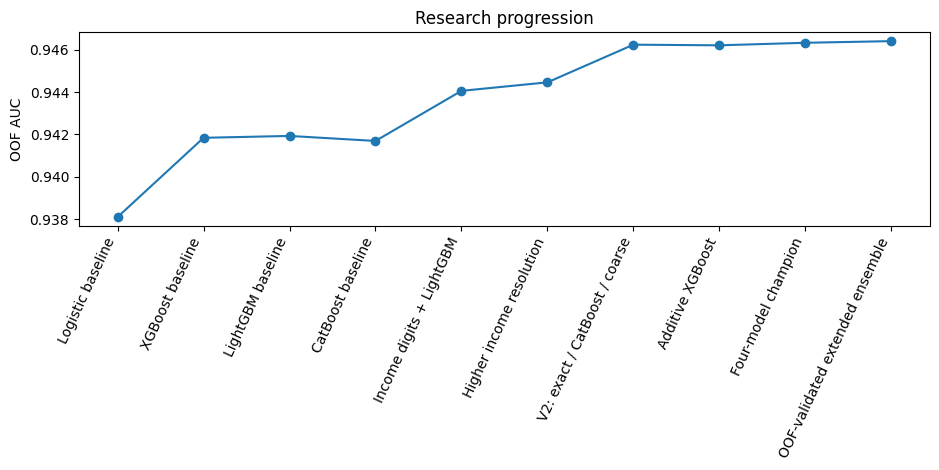

In [5]:
plt.figure(
    figsize=(9.5, 4.8)
)

plt.plot(
    range(len(history)),
    history["oof_auc"],
    marker="o",
)

plt.xticks(
    range(len(history)),
    history["stage"],
    rotation=65,
    ha="right",
)

plt.ylabel("OOF AUC")
plt.title("Research progression")
plt.tight_layout()
plt.show()

# 5. Core self-trained model views

The project did not force every model onto one universal feature matrix. Different representations were intentionally preserved when they produced different useful rankings.

## 5.1 LightGBM exact

`02_lgb_exact.ipynb` emphasizes high-resolution numeric representation:

- detailed income digits;
- income floors;
- train+test label-free frequency;
- original-data mean statistics;
- fold-fitted 600-quantile income bin;
- triple cross-fitted Target Encoding;
- three LightGBM seeds.

## 5.2 CatBoost

`03_catboost.ipynb` emphasizes categorical structure:

- explicit categorical columns;
- four categorical interaction keys;
- income digits and quantization;
- fold-local frequency;
- triple Target Encoding plus a selected-key extra encoding;
- two CatBoost seeds.

## 5.3 LightGBM coarse

`04_lgb_coarse.ipynb` deliberately uses a different statistical view:

- coarser income ladders;
- stronger TE smoothing;
- external original-data support / novelty / target-rate statistics;
- competition-vs-original log-odds lift;
- cross-fitted local target-rate windows over income and commute.

Its standalone AUC is lower, but its ensemble value is assessed by marginal contribution rather than standalone rank.

## 5.4 Additive XGBoost

`05_additive_xgb.ipynb` is the most explicit structural experiment:

- `max_bin=16384`;
- six income digits;
- fold-local frequency;
- triple Target Encoding;
- outer 10-fold / inner 10-fold;
- depth 4;
- `learning_rate=0.025`;
- `min_child_weight=10`;
- `reg_alpha=0.071`, `reg_lambda=2`;
- interaction constraints grouped by original source field.

Different representations of the same original field may interact within a tree, while arbitrary cross-field tree interactions are restricted.

In [6]:
component_auc = pd.DataFrame([
    (
        "lgb_exact",
        auc(data["lgb_exact_raw"]),
    ),
    (
        "CatBoost",
        auc(data["cat_raw"]),
    ),
    (
        "lgb_coarse",
        auc(data["lgb_coarse_raw"]),
    ),
    (
        "additive_XGB",
        auc(data["xgb_additive_raw"]),
    ),
    (
        "V2_blend",
        auc(data["v2_blend"]),
    ),
    (
        "four_model_champion",
        auc(data["champion4"]),
    ),
], columns=[
    "component",
    "oof_auc",
]).sort_values(
    "oof_auc",
    ascending=False,
)

component_auc

,component,oof_auc
5,four_model_champion,0.946335057
4,V2_blend,0.946245633
3,additive_XGB,0.946215002
0,lgb_exact,0.946145580
1,CatBoost,0.946126272
2,lgb_coarse,0.945830860


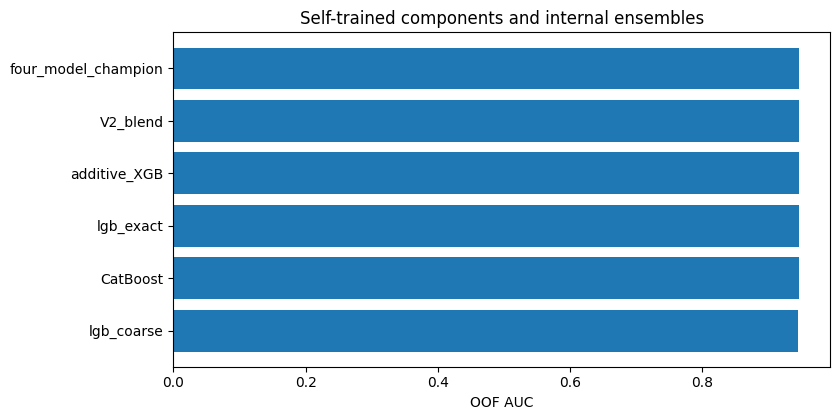

In [7]:
ordered = component_auc.sort_values(
    "oof_auc"
)

plt.figure(
    figsize=(8.5, 4.3)
)

plt.barh(
    ordered["component"],
    ordered["oof_auc"],
)

plt.xlabel("OOF AUC")
plt.title("Self-trained components and internal ensembles")
plt.tight_layout()
plt.show()

# 6. Prediction diversity: correlation is diagnostic, not sufficient

For an AUC-oriented ensemble, Spearman correlation is useful because it measures similarity in ordering.

But

$$
\text{low correlation}
\not\Rightarrow
\text{useful model}.
$$

A weak or noisy predictor can also be decorrelated. The project therefore used correlation to diagnose diversity, then required actual OOF improvement before keeping a component.

In [8]:
pred_frame = pd.DataFrame({
    "lgb_exact": data["lgb_exact_rank"],
    "CatBoost": data["cat_rank"],
    "lgb_coarse": data["lgb_coarse_rank"],
    "additive_XGB": data["xgb_additive_rank"],
    "V2_blend": data["v2_blend"],
    "champion4": data["champion4"],
})

corr = pred_frame.corr(
    method="spearman"
)

corr

,lgb_exact,CatBoost,lgb_coarse,additive_XGB,V2_blend,champion4
lgb_exact,1.000000000,0.991264986,0.994356132,0.996458439,0.998092823,0.998137937
CatBoost,0.991264986,1.000000000,0.988705399,0.992872073,0.996900847,0.995902921
lgb_coarse,0.994356132,0.988705399,1.000000000,0.993207719,0.995862493,0.995465943
additive_XGB,0.996458439,0.992872073,0.993207719,1.000000000,0.997138281,0.998986162
V2_blend,0.998092823,0.996900847,0.995862493,0.997138281,1.000000000,0.999526292
champion4,0.998137937,0.995902921,0.995465943,0.998986162,0.999526292,1.000000000


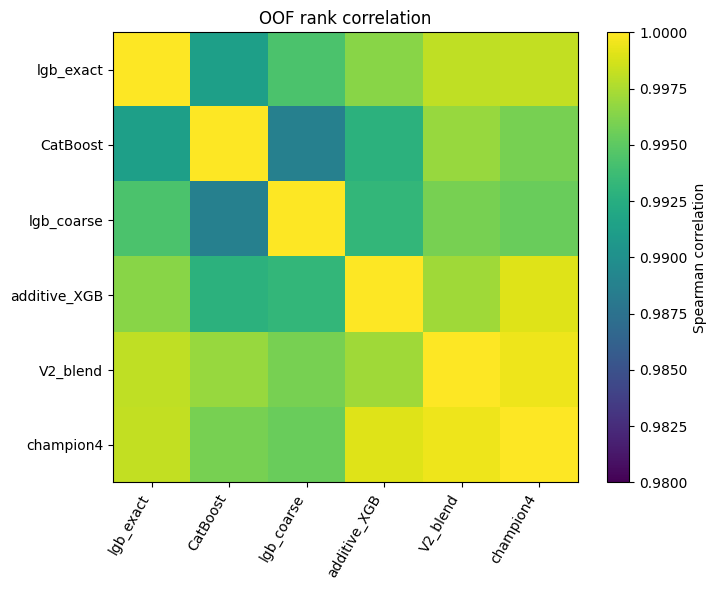

In [9]:
plt.figure(
    figsize=(7.3, 6.0)
)

img = plt.imshow(
    corr.to_numpy(),
    vmin=0.98,
    vmax=1.0,
    aspect="auto",
)

plt.colorbar(
    img,
    label="Spearman correlation",
)

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=60,
    ha="right",
)

plt.yticks(
    range(len(corr.index)),
    corr.index,
)

plt.title("OOF rank correlation")
plt.tight_layout()
plt.show()

# 7. From the V2 blend to the four-model champion

The three-view V2 ensemble was

$$
P_{\mathrm{V2}}
=
0.40R_{\mathrm{exact}}
+
0.40R_{\mathrm{cat}}
+
0.20R_{\mathrm{coarse}}.
$$

The additive XGBoost introduced a new structural ranking view. A frozen coarse weight scan evaluated

$$
P(w)
=
(1-w)P_{\mathrm{V2}}
+
wR_{\mathrm{XGB}}.
$$

The grid maximum occurred near $w=0.45$, but the region around $0.40$–$0.55$ was flat. The selected value was $w=0.40$, favoring a simple point near the top of the plateau rather than the numerically highest grid point.

Therefore

$$
P_{\mathrm{champion4}}
=
0.40R_{\mathrm{XGB}}
+
0.24R_{\mathrm{exact}}
+
0.24R_{\mathrm{cat}}
+
0.12R_{\mathrm{coarse}}.
$$

In [10]:
scan_df = pd.DataFrame({
    "xgb_weight": data["scan_weight"],
    "oof_auc": data["scan_oof_auc"],
    "cv_mean": data["scan_cv_mean"],
    "oof_gain": data["scan_oof_gain"],
})

scan_df

,xgb_weight,oof_auc,cv_mean,oof_gain
0,0.00,0.946245634,0.946244962,0.000000000
1,0.05,0.946264331,0.946263751,0.000018697
2,0.10,0.946280925,0.946280369,0.000035291
3,0.15,0.946295235,0.946294757,0.000049600
4,0.20,0.946307422,0.946306784,0.000061787
5,0.25,0.946317466,0.946317059,0.000071831
6,0.30,0.946325430,0.946325040,0.000079796
7,0.35,0.946331349,0.946331013,0.000085714
8,0.40,0.946335057,0.946334841,0.000089423
9,0.45,0.946336712,0.946336597,0.000091077


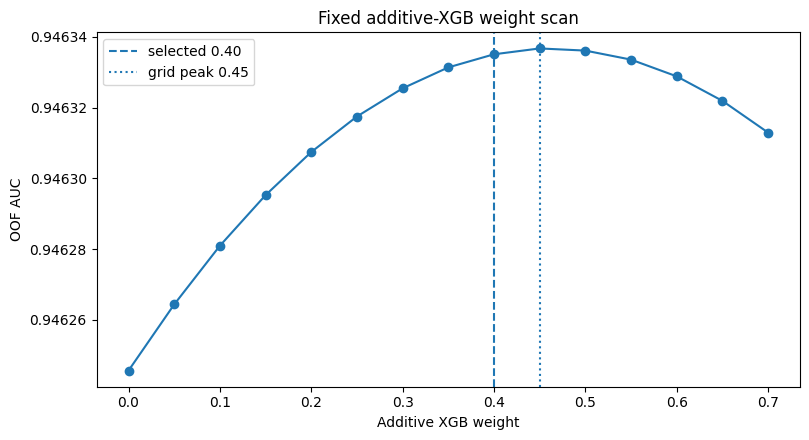

,configuration,oof_auc
0,V2 blend,0.946245633
1,Selected w=0.40,0.946335057
2,Grid peak,0.946336712


In [11]:
peak_row = scan_df.loc[
    scan_df["oof_auc"].idxmax()
]

selected_row = scan_df.loc[
    np.isclose(
        scan_df["xgb_weight"],
        0.40,
    )
].iloc[0]

plt.figure(
    figsize=(8.2, 4.5)
)

plt.plot(
    scan_df["xgb_weight"],
    scan_df["oof_auc"],
    marker="o",
)

plt.axvline(
    0.40,
    linestyle="--",
    label="selected 0.40",
)

plt.axvline(
    float(
        peak_row["xgb_weight"]
    ),
    linestyle=":",
    label=(
        "grid peak "
        f"{peak_row['xgb_weight']:.2f}"
    ),
)

plt.xlabel("Additive XGB weight")
plt.ylabel("OOF AUC")
plt.title("Fixed additive-XGB weight scan")
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame([
    (
        "V2 blend",
        auc(data["v2_blend"]),
    ),
    (
        "Selected w=0.40",
        auc(data["champion4"]),
    ),
    (
        "Grid peak",
        float(
            peak_row["oof_auc"]
        ),
    ),
], columns=[
    "configuration",
    "oof_auc",
])

# 8. Controlled experiments and negative results

Negative experiments are part of the research record because they identify which ideas did **not** survive the frozen validation rule.

The table below reports later controlled experiments relative to the current ensemble at the time they were tested.

The negative-experiment entries below come from historical experiment records. The rejected variants are not all distributed as runnable training notebooks in this repository.

In [12]:
ablations = pd.DataFrame([
    (
        "Third CatBoost seed",
        np.nan,
        -0.000000811,
        "1/5",
        "DROP",
    ),
    (
        "Probability blend at fixed weights",
        0.946327598,
        -0.000007459,
        "1/5",
        "DROP",
    ),
    (
        "Conditional TE + additive XGB",
        0.945998864,
        -0.000005361,
        "2/5",
        "DROP",
    ),
    (
        "Original-profile features",
        0.946082227,
        0.000003214,
        "4/5",
        "DROP",
    ),
    (
        "High-resolution income LightGBM",
        0.946059398,
        np.nan,
        "0/5",
        "DROP",
    ),
    (
        "Additive XGB without income digits",
        0.946209035,
        0.000002257,
        "4/5",
        "DROP",
    ),
    (
        "RealMLP fixed 20% probe",
        0.946009901,
        0.000016112,
        "4/5",
        "DROP",
    ),
    (
        "Train+test transductive frequency XGB",
        0.946242880,
        -0.000003246,
        "2/5",
        "DROP",
    ),
    (
        "Add original labeled 10k rows",
        0.946188220,
        -0.000006994,
        "2/5",
        "DROP",
    ),
    (
        "Window XGB fixed 20% probe",
        0.946207676,
        0.000044164,
        "5/5",
        "DROP individually",
    ),
    (
        "Hybrid LightGBM fixed probe",
        np.nan,
        0.000032551,
        "5/5",
        "DROP individually",
    ),
], columns=[
    "experiment",
    "standalone_or_candidate_oof",
    "fixed_probe_gain",
    "improved_reference_folds",
    "decision",
])

ablations

,experiment,standalone_or_candidate_oof,fixed_probe_gain,improved_reference_folds,decision
0,Third CatBoost seed,NaN,-0.000000811,1/5,DROP
1,Probability blend at fixed weights,0.946327598,-0.000007459,1/5,DROP
2,Conditional TE + additive XGB,0.945998864,-0.000005361,2/5,DROP
3,Original-profile features,0.946082227,0.000003214,4/5,DROP
4,High-resolution income LightGBM,0.946059398,NaN,0/5,DROP
5,Additive XGB without income digits,0.946209035,0.000002257,4/5,DROP
6,RealMLP fixed 20% probe,0.946009901,0.000016112,4/5,DROP
7,Train+test transductive frequency XGB,0.946242880,-0.000003246,2/5,DROP
8,Add original labeled 10k rows,0.946188220,-0.000006994,2/5,DROP
9,Window XGB fixed 20% probe,0.946207676,0.000044164,5/5,DROP individually


The late-stage pattern was consistent:

- many ideas produced changes on the order of only $10^{-6}$ to $10^{-5}$;
- several candidates improved 4/5 or 5/5 folds but remained below the frozen gain threshold;
- standalone strength and marginal ensemble value were not the same quantity;
- removing income digits from additive XGBoost changed little but did not improve enough to justify replacing the verified model.

The near-threshold Window XGB and Hybrid LightGBM results become important in the next section: neither was promoted individually, but their **joint correction structure** was complementary.

# 9. OOF-validated extended ensemble

After the four-model self-trained champion reached

$$
\mathrm{AUC}
=
0.946335057,
$$

two public OOF prediction views were evaluated:

- `Window XGB`
- `Hybrid LightGBM`

These are external/public OOF predictions, not self-trained components from notebooks `01–05`.

The equal blend

$$
P_{\mathrm{extended}}
=
\frac{
P_{\mathrm{champion4}}
+
R_{\mathrm{Window}}
+
R_{\mathrm{Hybrid}}
}{3}
$$

reached

$$
\boxed{0.946413088},
$$

for a gain of

$$
\boxed{+7.803\times10^{-5}}
$$

over the four-model champion.

In [13]:
extended_metrics = pd.DataFrame([
    (
        "four_model_champion",
        auc(data["champion4"]),
    ),
    (
        "window_XGB_public_OOF",
        auc(data["window_rank"]),
    ),
    (
        "hybrid_LGB_public_OOF",
        auc(data["hybrid_rank"]),
    ),
    (
        "equal_extended_ensemble",
        auc(data["extended_oof"]),
    ),
], columns=[
    "view",
    "oof_auc",
])

extended_metrics

,view,oof_auc
0,four_model_champion,0.946335057
1,window_XGB_public_OOF,0.946209307
2,hybrid_LGB_public_OOF,0.946264226
3,equal_extended_ensemble,0.946413088


## 9.1 Correction-vector complementarity

A useful diagnostic is not only the correlation of the predictions themselves, but also the correlation of how each external view **changes** the current champion.

Define

$$
\Delta_W
=
R_{\mathrm{Window}}
-
P_{\mathrm{champion4}},
$$

and

$$
\Delta_H
=
R_{\mathrm{Hybrid}}
-
P_{\mathrm{champion4}}.
$$

If these corrections are highly correlated, the two views largely push the champion in the same direction. Here their correction correlation was much lower.

In [14]:
d_window = (
    data["window_rank"]
    - data["champion4"]
)

d_hybrid = (
    data["hybrid_rank"]
    - data["champion4"]
)

correction_stats = pd.DataFrame({
    "metric": [
        "Spearman(champion, Window)",
        "Spearman(champion, Hybrid)",
        "Pearson(correction_Window, correction_Hybrid)",
        "Spearman(correction_Window, correction_Hybrid)",
    ],
    "value": [
        spearmanr(
            data["champion4"],
            data["window_rank"],
        ).statistic,
        spearmanr(
            data["champion4"],
            data["hybrid_rank"],
        ).statistic,
        np.corrcoef(
            d_window,
            d_hybrid,
        )[0, 1],
        spearmanr(
            d_window,
            d_hybrid,
        ).statistic,
    ],
})

correction_stats

,metric,value
0,"Spearman(champion, Window)",0.996858851
1,"Spearman(champion, Hybrid)",0.997733413
2,"Pearson(correction_Window, correction_Hybrid)",0.329146932
3,"Spearman(correction_Window, correction_Hybrid)",0.327436488


The Pearson correlation between the two correction vectors is about **0.329**, which helps explain why two individually sub-threshold additions could become useful together.

In [15]:
fold_gain = fold_auc_table(
    data["champion4"],
    data["extended_oof"],
)

fold_gain

,fold,old_auc,new_auc,delta
0,1,0.945409046,0.945468917,0.000059871
1,2,0.946017051,0.946152127,0.000135076
2,3,0.947188638,0.947255646,0.000067008
3,4,0.946645211,0.946730503,0.000085292
4,5,0.946414261,0.946454980,0.000040720


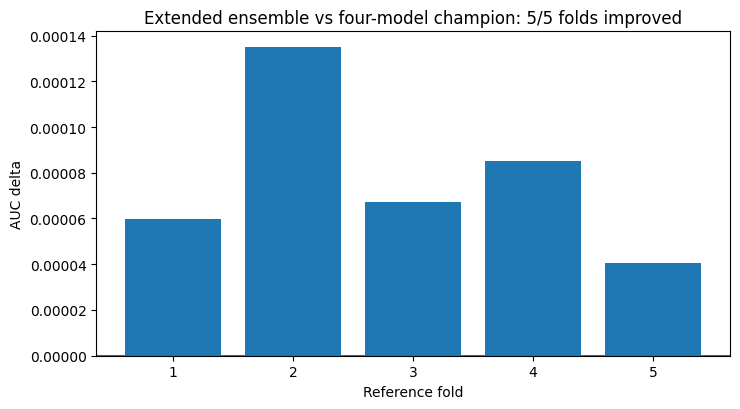

In [16]:
plt.figure(
    figsize=(7.5, 4.2)
)

plt.bar(
    fold_gain["fold"].astype(str),
    fold_gain["delta"],
)

plt.axhline(0)
plt.xlabel("Reference fold")
plt.ylabel("AUC delta")
plt.title(
    "Extended ensemble vs four-model champion: 5/5 folds improved"
)
plt.tight_layout()
plt.show()

## 9.2 Equal blend versus a cross-fitted stack

As a robustness check, a 5-fold cross-fitted Logistic Regression meta-model on the available OOF prediction columns was fitted using only

$$
[
P_{\mathrm{champion4}},
R_{\mathrm{Window}},
R_{\mathrm{Hybrid}}
].
$$

The more complex stack did not materially improve over the equal blend.

In [17]:
X_meta = np.column_stack([
    data["champion4"],
    data["window_rank"],
    data["hybrid_rank"],
])

y = data["y_true"]
fold = data["fold5"]

meta_oof = np.empty(
    len(y),
    dtype=float,
)

meta_rows = []

for f in sorted(
    np.unique(fold)
):
    valid = fold == f
    train_mask = ~valid

    model = LogisticRegression(
        C=1.0,
        max_iter=1000,
        solver="lbfgs",
    )

    model.fit(
        X_meta[train_mask],
        y[train_mask],
    )

    meta_oof[valid] = (
        model.predict_proba(
            X_meta[valid]
        )[:, 1]
    )

    meta_rows.append(
        (
            int(f),
            *model.coef_[0],
            model.intercept_[0],
        )
    )

meta_auc = roc_auc_score(
    y,
    meta_oof,
)

pd.DataFrame([
    (
        "simple equal blend",
        auc(data["extended_oof"]),
    ),
    (
        "cross-fitted logistic stack",
        meta_auc,
    ),
], columns=[
    "method",
    "oof_auc",
])

,method,oof_auc
0,simple equal blend,0.946413088
1,cross-fitted logistic stack,0.946411811


The equal blend remains preferable here because it is simpler and is essentially tied with the cross-fitted stack.

This is an example of using a more complex method as a **robustness check**, not automatically promoting it because it has more parameters.

# 10. Competition-stage external test-prediction ensemble

The next stage must be separated from OOF research.

After the OOF-validated ensemble was complete, several public Kaggle test predictions without trustworthy aligned OOF were used as external competition views.

The fixed update was

$$
P_{\mathrm{new}}
=
0.8R(P_{\mathrm{current}})
+
0.2R(P_{\mathrm{external}}).
$$

Because these candidates were evaluated through leaderboard feedback rather than project OOF, their gains are reported only as **competition-stage post-processing**.

In [18]:
external_corr = pd.DataFrame([
    (
        "OOF-validated extended submission",
        "external public blend A",
        spearmanr(
            data["extended_test"],
            data["external_A"],
        ).statistic,
    ),
    (
        "after external A",
        "tie-breaking public submission",
        spearmanr(
            data["stage_external"],
            data["tie_break"],
        ).statistic,
    ),
    (
        "after tie-break",
        "micro-blend public submission",
        spearmanr(
            data["stage_tiebreak"],
            data["microblend"],
        ).statistic,
    ),
], columns=[
    "current_stage",
    "candidate",
    "spearman",
])

external_corr

,current_stage,candidate,spearman
0,OOF-validated extended submission,external public blend A,0.997997285
1,after external A,tie-breaking public submission,0.999064151
2,after tie-break,micro-blend public submission,0.999355560


In [19]:
leaderboard = pd.DataFrame([
    (
        "OOF-validated extended ensemble",
        0.94648,
        0.94541,
    ),
    (
        "+ external rank blend",
        0.94651,
        0.94542,
    ),
    (
        "+ tie-break view",
        0.94653,
        0.94543,
    ),
    (
        "+ micro-blend view",
        0.94655,
        0.94544,
    ),
], columns=[
    "submission_stage",
    "public_auc",
    "private_auc",
])

leaderboard

,submission_stage,public_auc,private_auc
0,OOF-validated extended ensemble,0.94648,0.94541
1,+ external rank blend,0.94651,0.94542
2,+ tie-break view,0.94653,0.94543
3,+ micro-blend view,0.94655,0.94544


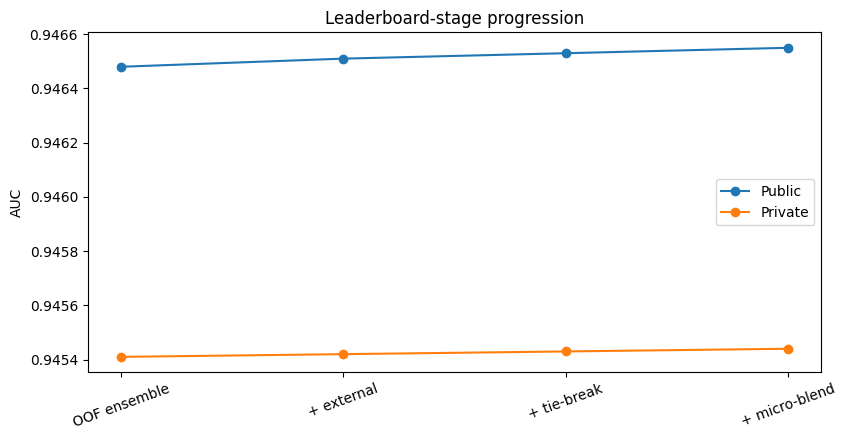

In [20]:
x = np.arange(
    len(leaderboard)
)

plt.figure(
    figsize=(8.6, 4.5)
)

plt.plot(
    x,
    leaderboard["public_auc"],
    marker="o",
    label="Public",
)

plt.plot(
    x,
    leaderboard["private_auc"],
    marker="o",
    label="Private",
)

plt.xticks(
    x,
    [
        "OOF ensemble",
        "+ external",
        "+ tie-break",
        "+ micro-blend",
    ],
    rotation=20,
)

plt.ylabel("AUC")
plt.title("Leaderboard-stage progression")
plt.legend()
plt.tight_layout()
plt.show()

The Private score improved at every one of these late stages, but the increments were only $10^{-5}$. These results do not retroactively turn leaderboard-stage selection into unbiased validation evidence.

# 11. Final competition result

The final selected submission achieved:

- **Private AUC:** 0.94544
- **Public AUC:** 0.94655
- **Final rank:** 350 / 3576
- **Percentile:** Top 9.8%

The OOF-validated extended ensemble was also retained as a separate submission and scored Private AUC **0.94541**.

The final leaderboard submission therefore contains a competition-stage external prediction ensemble on top of the OOF-validated research pipeline.

In [21]:
final_rank = 350
participants = 3576
top_pct = (
    final_rank
    / participants
    * 100
)

pd.DataFrame({
    "metric": [
        "Private AUC",
        "Public AUC",
        "Final rank",
        "Participants",
        "Top percentile",
    ],
    "value": [
        0.94544,
        0.94655,
        final_rank,
        participants,
        f"{top_pct:.2f}%",
    ],
})

,metric,value
0,Private AUC,0.94544
1,Public AUC,0.94655
2,Final rank,350
3,Participants,3576
4,Top percentile,9.79%


# 12. Research conclusions

### 12.1 Representation created the largest early gains

The largest early improvements came from changing how the data were represented rather than from blind parameter search.

Income in particular was represented through combinations of:

- raw continuous values;
- digit decomposition;
- coarse integer quantization;
- frequency information;
- multiple smoothed Target Encodings;
- local target-rate structure.

The effect diminished as the representation space became saturated.

### 12.2 Standalone AUC is not the ensemble objective

The project repeatedly observed that

$$
\text{strong standalone model}
\not\Rightarrow
\text{large marginal ensemble gain}.
$$

The operational objective became

$$
\Delta\mathrm{AUC}_{\mathrm{ensemble}},
$$

under a frozen OOF rule.

### 12.3 Correlation should be interpreted together with correction structure

Prediction correlation identifies near-duplicates, but the correction-vector analysis was more informative for the late extended ensemble.

The two public OOF views were each individually below the keep threshold, yet their corrections relative to the champion had only moderate correlation and the joint equal blend improved all 5 reference folds.

### 12.4 Frozen decision rules reduced late-stage overfitting

The $5\times10^{-5}$ gain threshold and 4/5-fold rule were deliberately conservative. They stopped the search from repeatedly changing weights or parameters to rescue weak experiments.

### 12.5 Validation evidence and leaderboard evidence are different

The final project contains three distinct forms of evidence:

1. self-trained OOF model research;
2. OOF-validated external/public prediction views;
3. leaderboard-stage test-only external blending.

The reported conclusions keep these categories separate.

# 13. Project artifact map

The GitHub project is organized as:

```text
01_logistic_baseline.ipynb
02_lgb_exact.ipynb
03_catboost.ipynb
04_lgb_coarse.ipynb
05_additive_xgb.ipynb
06_final_research.ipynb
assets/
    S6E9_research_assets_part01.npz ... partNN.npz
```

Notebooks `01–05` contain the canonical model-training pipelines. This notebook contains the project-level validation and ensemble analysis.

The saved NPZ asset contains aligned OOF/test predictions needed to reproduce the analysis without retraining the heavy models.

In [22]:
report = pd.Series(
    {
        "Logistic reproduced OOF": 0.938099,
        "LGB exact OOF": auc(
            data["lgb_exact_raw"]
        ),
        "CatBoost OOF": auc(
            data["cat_raw"]
        ),
        "LGB coarse OOF": auc(
            data["lgb_coarse_raw"]
        ),
        "Additive XGB OOF": auc(
            data["xgb_additive_raw"]
        ),
        "V2 OOF": auc(
            data["v2_blend"]
        ),
        "Four-model champion OOF": auc(
            data["champion4"]
        ),
        "Extended OOF ensemble": auc(
            data["extended_oof"]
        ),
        "Extended gain vs champion": (
            auc(data["extended_oof"])
            - auc(data["champion4"])
        ),
        "Window/Hybrid correction Pearson": np.corrcoef(
            data["window_rank"]
            - data["champion4"],
            data["hybrid_rank"]
            - data["champion4"],
        )[0, 1],
        "Final Private AUC": 0.94544,
        "Final rank": "350 / 3576",
    },
    name="value",
)

report

Logistic reproduced OOF                0.938099
LGB exact OOF                        0.94614558
CatBoost OOF                        0.946126272
LGB coarse OOF                       0.94583086
Additive XGB OOF                    0.946215002
V2 OOF                              0.946245633
Four-model champion OOF             0.946335057
Extended OOF ensemble               0.946413088
Extended gain vs champion           0.000078031
Window/Hybrid correction Pearson    0.329146932
Final Private AUC                       0.94544
Final rank                           350 / 3576
Name: value, dtype: object

# 14. Final results

The main project-level results are:

- V2 three-view ensemble OOF AUC: **0.946245633**
- Additive XGBoost OOF AUC: **0.946215002**
- Four-model internal champion OOF AUC: **0.946335057**
- OOF-validated extended ensemble AUC: **0.946413088**

The final selected competition submission achieved:

- Private AUC: **0.94544**
- Public AUC: **0.94655**
- Final rank: **350 / 3576**
- Final percentile: **Top 9.8%**

The OOF-validated ensemble and the later leaderboard-stage external prediction blends are treated separately throughout this notebook.